# Superstore Sales Data Analysis

## Project Overview
Explore sales, dataset profit, discounts, and loss concentration in the 2014–2017 Superstore extract. Each row is an order line, not a unique order; order counts use distinct `Order ID` values.

**Reading guide:** [Data quality](#data-quality) · [Overall performance](#overall-performance) · [Regional profitability](#regional-profitability) · [Product losses](#product-losses) · [Time patterns](#time-patterns) · [Business insights](#business-insights)

**Metric definitions:** Net profit is the sum of the supplied `Profit` column, including positive, zero, and negative rows. Gross loss is the positive magnitude of negative row-level `Profit` only, before offsetting profitable rows; it is not an accounting gross-profit measure. Profit margin is summed profit / summed sales × 100, not an average of row margins. Discount comparisons are unweighted means across order lines. Monetary amounts are presented in dollars, following the dataset convention.

## 1. Import Libraries
Import analysis and display tools. Run all cells in order from the project root or the `notebooks` folder.

In [1]:
import calendar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

def show_table(table, caption):
    """Format numeric results consistently while retaining numeric analysis tables."""
    table = table.copy()
    labels = {
        'Total_Sales': 'Sales ($)', 'Sales': 'Sales ($)',
        'Total_Profit': 'Net profit ($)', 'Net_Profit': 'Net profit ($)',
        'Profit': 'Row profit ($)', 'Profit_Margin': 'Profit margin (%)',
        'Sales_Count': 'Order lines', 'Average_Discount': 'Mean discount (%)',
        'Gross_Loss': 'Gross loss ($)', 'Loss_Share': 'Share of all gross loss (%)',
    }
    table = table.rename(columns=labels)
    table.columns = [str(c).replace('_', ' ') for c in table.columns]
    if isinstance(table.index, pd.MultiIndex):
        table.index.names = [str(n).replace('_', ' ') if n else n for n in table.index.names]
    formats = {}
    for column in table.columns:
        if pd.api.types.is_numeric_dtype(table[column]):
            formats[column] = '${:,.2f}' if '($)' in column else ('{:,.0f}' if pd.api.types.is_integer_dtype(table[column]) else '{:,.2f}')
    display(table.style.format(formats).set_caption(caption))

## 2. Data Loading

The Superstore dataset is loaded into a Pandas DataFrame for further exploration and analysis.

In [2]:
from pathlib import Path

# Support launching Jupyter from the project root or the notebooks directory.
root = Path.cwd()
if not (root / "data").is_dir():
    root = root.parent
csv_path = root / "data" / "Sample - Superstore.csv"
if not csv_path.is_file():
    raise FileNotFoundError(f"Place the Superstore CSV file here: {csv_path}")

try:
    df = pd.read_csv(csv_path, encoding="utf-8-sig")
except UnicodeDecodeError:
    try:
        df = pd.read_csv(csv_path, encoding="cp1252")
    except UnicodeDecodeError:
        df = pd.read_csv(csv_path, encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Data Understanding

This section examines the dataset's structure, dimensions, data types, and statistical properties to gain an initial understanding of the available information.

### 3.1 Dataset Dimensions

Count order lines and available fields before any transformations.

In [3]:
pd.DataFrame({'Order lines': [len(df)], 'Columns': [df.shape[1]]})

,Order lines,Columns
0,9994,21


The dataset consists of **9,994 rows and 21 columns**, containing information about sales order lines, customers, products, and profitability.

### 3.2 Data Types

The data types of each column are examined to identify potential type conversions required for further analysis.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

**Key Observations**

- **Numerical variables:** Sales, Profit, Discount, and Quantity have appropriate numerical data types.
- **Date variables:** Order Date and Ship Date are stored as strings and require conversion to datetime.
- **Geographical identifiers:** Postal Code is stored as an integer, although it represents a location identifier rather than a numerical measurement.

### 3.3 Data Type Conversion

Parse the two date fields with an explicit month/day/year format. Treat Postal Code as a five-character identifier, restoring leading zeros lost by numeric CSV inference.

In [5]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
df['Postal Code'] = df['Postal Code'].astype('string').str.zfill(5)
display(df[['Order Date', 'Ship Date', 'Postal Code']].dtypes.to_frame('Converted type'))

,Converted type
Order Date,datetime64[us]
Ship Date,datetime64[us]
Postal Code,string


**Finding:** Both dates now use datetime types; Postal Code is a string identifier. Conversion raises an error on incompatible dates rather than silently dropping rows.

<a id="data-quality"></a>

## 4. Data Quality Assessment

The dataset is examined for missing values and duplicate records to assess its reliability before further analysis.

### 4.1 Missing Values

Count missing entries per column; avoid printing a row-by-row Boolean matrix.

In [6]:
df.isna().sum().to_frame('Missing values')

,Missing values
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


No missing values were detected across the 21 columns.

### 4.2 Duplicate Records

Check full-row duplication and uniqueness of the row identifier. Repeated order IDs are expected for multi-line orders.

In [7]:
pd.DataFrame({'Fully duplicated rows': [df.duplicated().sum()], 'Repeated Row IDs': [df['Row ID'].duplicated().sum()]})

,Fully duplicated rows,Repeated Row IDs
0,0,0


No fully duplicated rows or repeated Row IDs were found. This check does not rule out business duplicates entered under different identifiers; no rows are removed.

### 4.3 Numerical Data Validation

Descriptive statistics are used to examine the ranges of key numerical variables and identify potentially invalid values.

In [8]:
display(df[['Sales', 'Profit', 'Quantity', 'Discount']].describe().round(2))
quality_checks = pd.Series({
    'Missing numerical values': int(df[['Sales', 'Profit', 'Quantity', 'Discount']].isna().sum().sum()),
    'Non-finite numerical values': int((~np.isfinite(df[['Sales', 'Profit', 'Quantity', 'Discount']])).sum().sum()),
    'Nonpositive sales': int(df['Sales'].le(0).sum()),
    'Nonpositive quantities': int(df['Quantity'].le(0).sum()),
    'Discounts outside [0, 1]': int((~df['Discount'].between(0, 1)).sum()),
    'Ship dates before order dates': int(df['Ship Date'].lt(df['Order Date']).sum()),
})
display(quality_checks.to_frame('Flagged rows / values'))
assert quality_checks.eq(0).all(), 'Review flagged source-data issues before interpreting the EDA.'

,Sales,Profit,Quantity,Discount
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,28.66,3.79,0.16
std,623.25,234.26,2.23,0.21
min,0.44,-6599.98,1.00,0.00
25%,17.28,1.73,2.00,0.00
50%,54.49,8.67,3.00,0.20
75%,209.94,29.36,5.00,0.20
max,22638.48,8399.98,14.00,0.80


,Flagged rows / values
Missing numerical values,0
Non-finite numerical values,0
Nonpositive sales,0
Nonpositive quantities,0
"Discounts outside [0, 1]",0
Ship dates before order dates,0


**Key observations**

- Sales and Quantity are positive; Discount ranges from 0% to 80% and remains within [0, 1]. Numerical values are finite and shipping does not precede ordering.
- Negative Profit values are retained as loss-making order lines. Passing these checks does not verify the underlying accounting or completeness of the source.

## 5. Exploratory Data Analysis

This section explores sales performance, profitability, product categories, and regional trends to identify key business insights.

<a id="overall-performance"></a>

### 5.1 Overall Sales Performance

This section evaluates overall sales performance by calculating total sales, total profit, and profit margin.

In [9]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
profit_margin = total_profit / total_sales * 100
total_orders = df['Order ID'].nunique()
average_order_value = total_sales / total_orders
show_table(pd.DataFrame({
    'Sales ($)': [total_sales], 'Net profit ($)': [total_profit],
    'Profit margin (%)': [profit_margin], 'Unique orders': [total_orders],
    'Average order value ($)': [average_order_value],
}), 'Overall performance | all 9,994 order lines, 2014–2017')

,Sales ($),Net profit ($),Profit margin (%),Unique orders,Average order value ($)
0,"$2,297,200.86","$286,397.02",12.47,"5,009",$458.61


**Key Findings**

- Total sales reached approximately `$2.30 million`, generating `$286.4K` in profit.
- The overall profit margin was 12.47%, equivalent to approximately `$12.47` in dataset profit for every `$100` in sales. 
- A total of 5,009 unique orders were recorded, with an average order value of `$458.61`.

### 5.2 Category Performance

This section analyzes sales, profit, and profit margins across product categories to compare their performance and identify potential profitability issues.

In [10]:
category_performance = df.groupby('Category').agg(Total_Sales=('Sales', 'sum'), Total_Profit=('Profit', 'sum'))
category_performance['Profit_Margin'] = category_performance['Total_Profit'] / category_performance['Total_Sales'] * 100
show_table(category_performance.sort_values('Total_Sales', ascending=False), 'Category performance | all order lines')

,Sales ($),Net profit ($),Profit margin (%)
Category,,,
Technology,"$836,154.03","$145,454.95",17.40
Furniture,"$741,999.80","$18,451.27",2.49
Office Supplies,"$719,047.03","$122,490.80",17.04


**Key findings**

- Technology leads sales (`$836,154.03`) and net profit (`$145,454.95`), with a 17.40% margin.
- Office Supplies has a 17.04% margin on `$719,047.03` of sales.
- Furniture has `$741,999.80` of sales but a 2.49% margin, warranting a closer loss review.

#### Furniture Loss-Making Order Lines

Compare negative and positive row-level profit and unweighted average discounts within Furniture. Zero-profit rows are excluded from the positive/loss discount comparison.

In [11]:
furniture_df = df[df['Category'] == 'Furniture']
furniture_loss_count = int(furniture_df['Profit'].lt(0).sum())
furniture_total_count = len(furniture_df)
furniture_loss_rate = furniture_loss_count / furniture_total_count * 100
furniture_total_loss = -furniture_df.loc[furniture_df['Profit'].lt(0), 'Profit'].sum()
furniture_positive_profit = furniture_df.loc[furniture_df['Profit'].gt(0), 'Profit'].sum()
loss_avg_discount = furniture_df.loc[furniture_df['Profit'].lt(0), 'Discount'].mean() * 100
positive_avg_discount = furniture_df.loc[furniture_df['Profit'].gt(0), 'Discount'].mean() * 100
show_table(pd.DataFrame({
    'Order lines': [furniture_total_count], 'Loss lines': [furniture_loss_count],
    'Loss line rate (%)': [furniture_loss_rate], 'Gross loss ($)': [furniture_total_loss],
    'Positive-row profit ($)': [furniture_positive_profit],
    'Mean discount, loss lines (%)': [loss_avg_discount],
    'Mean discount, positive lines (%)': [positive_avg_discount],
}).T.rename(columns={0: 'Value'}).rename_axis('Metric'), 'Furniture | row counts, dollar amounts, and unweighted discount rates')
print(f"Furniture Discount-Profit Pearson correlation: {furniture_df['Discount'].corr(furniture_df['Profit']):.2f}")

,Value
Metric,
Order lines,"2,121.00"
Loss lines,714.00
Loss line rate (%),33.66
Gross loss ($),"60,936.11"
Positive-row profit ($),"79,387.38"
"Mean discount, loss lines (%)",36.71
"Mean discount, positive lines (%)",7.19


Furniture Discount-Profit Pearson correlation: -0.48


**Key Findings**

- Of the 2,121 Furniture sales rows, 714 (33.66%) resulted in losses.
- Loss-making sales generated approximately `$60.94K` in total losses, while profitable sales generated `$79.39K` in positive profit.
- The correlation between Discount and Profit was -0.48, indicating a moderate negative relationship.
- Loss-making sales had an average discount of 36.71%, compared with 7.19% for profitable sales.
- These findings suggest that higher discounts are associated with lower profitability in the Furniture category.

### 5.3 Furniture Sub-Category Analysis
This analysis examines profitability across Furniture sub-categories to identify which product groups contribute to profits and which contribute to losses.

In [12]:
furniture_subcategories = furniture_df.groupby('Sub-Category').agg(Total_Sales=('Sales', 'sum'), Total_Profit=('Profit', 'sum'))
furniture_subcategories['Profit_Margin'] = furniture_subcategories['Total_Profit'] / furniture_subcategories['Total_Sales'] * 100
show_table(furniture_subcategories, 'Furniture sub-categories | sales, net profit, weighted margin')

,Sales ($),Net profit ($),Profit margin (%)
Sub-Category,,,
Bookcases,"$114,880.00","$-3,472.56",-3.02
Chairs,"$328,449.10","$26,590.17",8.10
Furnishings,"$91,705.16","$13,059.14",14.24
Tables,"$206,965.53","$-17,725.48",-8.56


**Key Findings**

- Tables generated approximately `$206.97K` in sales but recorded a net loss of `$17.73K`, with a profit margin of -8.56%.
- Bookcases also recorded a negative profit margin of -3.02%.
- Chairs generated the highest total profit at approximately `$26.59K`, with a profit margin of 8.10%.
- Furnishings achieved the highest profit margin at 14.24%, despite having the lowest total sales among Furniture sub-categories.
- These findings indicate that Tables and Bookcases are the main contributors to Furniture's profitability challenges.

#### Tables: Discount Comparison

Compare the loss frequency and mean discount for Tables order lines; positive-profit and negative-profit groups exclude break-even lines.

In [13]:
tables_df = furniture_df[furniture_df['Sub-Category'] == 'Tables']
tables_loss = tables_df[tables_df['Profit'] < 0]
tables_profit = tables_df[tables_df['Profit'] > 0]
tables_loss_rate = len(tables_loss) / len(tables_df) * 100
tables_discount_profile = tables_df.assign(Profit_Status=np.select(
    [tables_df['Profit'].lt(0), tables_df['Profit'].gt(0)], ['Loss', 'Positive profit'], default='Break-even'
)).groupby('Profit_Status').agg(Order_Lines=('Profit', 'size'), Average_Discount=('Discount', 'mean'))
tables_discount_profile['Average_Discount'] *= 100
print(f'Tables: {len(tables_loss)} loss-making lines out of {len(tables_df)} ({tables_loss_rate:.2f}%).')
show_table(tables_discount_profile, 'Tables | order-line counts and unweighted mean discounts (%)')

Tables: 203 loss-making lines out of 319 (63.64%).


,Order Lines,Mean discount (%)
Profit_Status,,
Break-even,2,30.00
Loss,203,36.53
Positive profit,114,7.54


**Key Findings**

- 63.64% of Tables sales order lines resulted in losses.
- Loss-making order lines had an average discount of 36.53%, compared with 7.54% for profitable order lines.
- The findings suggest an association between higher discounts and negative profitability, but do not establish causation.
- Tables is a key area for further investigation into discounting practices.

### 5.4 Sub-Category Profitability Overview

This analysis evaluates sales, profit, and profit margins across all product sub-categories to identify underperforming groups and prioritize areas for further investigation.

Rather than applying the same detailed analysis to every category, the focus is on detecting significant profitability issues.

In [14]:
subcategory_performance = df.groupby(
    ["Category", "Sub-Category"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

subcategory_performance["Profit_Margin"] = (
    subcategory_performance["Total_Profit"]
    / subcategory_performance["Total_Sales"]
) * 100

show_table(subcategory_performance, 'All 17 sub-categories | weighted profit margins')

low_margin_subcategories = subcategory_performance[
    subcategory_performance["Profit_Margin"] < 5
]



**Key Findings**

- Four sub-categories have profit margins below the selected 5% threshold.
- Tables (-8.56%), Bookcases (-3.02%), and Supplies (-2.55%) recorded negative profit margins.
- Machines generated approximately `$189.24K` in sales but achieved a profit margin of only 1.79%.
- Supplies and Machines were identified for further investigation, while Furniture-related profitability issues were examined in previous sections.

*Note: The 5% threshold is an exploratory criterion, not an established industry benchmark.*

#### Supplies: Loss and Discount Profile

Compare loss frequency, gross loss, positive-row profit, and unweighted discounts for Supplies.

In [15]:
supplies_df = df[df['Sub-Category'] == 'Supplies']
supplies_loss = supplies_df[supplies_df['Profit'] < 0]
supplies_loss_rate = len(supplies_loss) / len(supplies_df) * 100
print(f'Supplies: {len(supplies_loss)} loss-making lines out of {len(supplies_df)} ({supplies_loss_rate:.2f}%).')
supplies_profile = supplies_df.assign(Profit_Status=np.select(
    [supplies_df['Profit'].lt(0), supplies_df['Profit'].gt(0)], ['Loss', 'Positive profit'], default='Break-even'
)).groupby('Profit_Status').agg(Order_Lines=('Profit', 'size'), Total_Profit=('Profit', 'sum'), Average_Discount=('Discount', 'mean'))
supplies_profile['Average_Discount'] *= 100
show_table(supplies_profile, 'Supplies | signed group net profit and unweighted mean discounts (%)')

Supplies: 33 loss-making lines out of 190 (17.37%).


,Order Lines,Net profit ($),Mean discount (%)
Profit_Status,,,
Loss,33,"$-3,015.62",20.00
Positive profit,157,"$1,826.52",5.10


**Supplies — Key Findings**

- Supplies recorded a net loss of approximately `$1,189.10`, with a profit margin of -2.55%.
- Only 17.37% of sales rows were loss-making, but their combined losses of `$3,015.62` exceeded the `$1,826.52` generated by profitable rows.
- Loss-making sales had an average discount of 20.00%, compared with 5.10% for profitable sales.
- Higher discounts were associated with loss-making order lines, although the results do not establish causation.

#### Machines: Loss and Discount Profile

Use the same row-level comparison for Machines to distinguish high revenue from profitability.

In [16]:
machines_df = df[df['Sub-Category'] == 'Machines']
machines_loss = machines_df[machines_df['Profit'] < 0]
machines_loss_rate = len(machines_loss) / len(machines_df) * 100
print(f'Machines: {len(machines_loss)} loss-making lines out of {len(machines_df)} ({machines_loss_rate:.2f}%).')
machines_profile = machines_df.assign(Profit_Status=np.select(
    [machines_df['Profit'].lt(0), machines_df['Profit'].gt(0)], ['Loss', 'Positive profit'], default='Break-even'
)).groupby('Profit_Status').agg(Order_Lines=('Profit', 'size'), Total_Profit=('Profit', 'sum'), Average_Discount=('Discount', 'mean'))
machines_profile['Average_Discount'] *= 100
show_table(machines_profile, 'Machines | signed group net profit and unweighted mean discounts (%)')

Machines: 44 loss-making lines out of 115 (38.26%).


,Order Lines,Net profit ($),Mean discount (%)
Profit_Status,,,
Loss,44,"$-30,118.67",58.18
Positive profit,71,"$33,503.43",13.52


**Machines — Key Findings**

- Machines generated approximately `$189.24K` in sales but achieved a profit margin of only 1.79%.
- 38.26% of sales rows were loss-making.
- Profitable order lines generated `$33,503.43`, while loss-making order lines resulted in `$30,118.67` in losses.
- Loss-making sales had an average discount of 58.18%, compared with 13.52% for profitable sales.
- The substantial discount difference suggests that discounting practices warrant further investigation, although causation has not been established.

<a id="regional-profitability"></a>

### 5.5 Regional Profitability Analysis

This analysis examines sales, profit, and profit margins across different regions to identify geographical differences in business performance.

The objective is to detect underperforming regions and determine whether further investigation is needed into regional profitability.

In [17]:
regional_performance = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

regional_performance["Profit_Margin"] = (
    regional_performance["Total_Profit"]
    / regional_performance["Total_Sales"]
) * 100

show_table(regional_performance, 'Regional performance | all categories')

,Sales ($),Net profit ($),Profit margin (%)
Region,,,
Central,"$501,239.89","$39,706.36",7.92
East,"$678,781.24","$91,522.78",13.48
South,"$391,721.91","$46,749.43",11.93
West,"$725,457.82","$108,418.45",14.94


#### Central Region Drill-Down

Compare Central categories and then Furniture sub-categories to locate net-profit weaknesses.

In [18]:
central_df = df[df["Region"] == "Central"]

central_category_performance = central_df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

central_category_performance["Profit_Margin"] = (
    central_category_performance["Total_Profit"]
    / central_category_performance["Total_Sales"]
) * 100

show_table(central_category_performance, 'Central region | category performance')

central_furniture = central_df[
    central_df["Category"] == "Furniture"
]

central_furniture_performance = central_furniture.groupby(
    "Sub-Category"
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

central_furniture_performance["Profit_Margin"] = (
    central_furniture_performance["Total_Profit"]
    / central_furniture_performance["Total_Sales"]
) * 100

show_table(central_furniture_performance, 'Central Furniture | sub-category performance')

,Sales ($),Net profit ($),Profit margin (%)
Category,,,
Furniture,"$163,797.16","$-2,871.05",-1.75
Office Supplies,"$167,026.42","$8,879.98",5.32
Technology,"$170,416.31","$33,697.43",19.77


,Sales ($),Net profit ($),Profit margin (%)
Sub-Category,,,
Bookcases,"$24,157.18","$-1,997.90",-8.27
Chairs,"$85,230.65","$6,592.72",7.74
Furnishings,"$15,254.37","$-3,906.22",-25.61
Tables,"$39,154.97","$-3,559.65",-9.09


#### Central Furnishings: Discounts and Profit Status

Compare mean discounts and group sizes for this observed loss pocket. Differences alone cannot identify the effect of changing discounts.

In [19]:
central_furnishings = central_furniture[
    central_furniture["Sub-Category"] == "Furnishings"
]

furnishings_loss_rate = (
    central_furnishings["Profit"].lt(0).mean() * 100
)

furnishings_discount_comparison = (
    central_furnishings.assign(
        Profit_Status=central_furnishings["Profit"].apply(
            lambda profit: "Loss" if profit < 0
            else "Profit" if profit > 0
            else "Break-even"
        )
    )
    .groupby("Profit_Status")
    .agg(Order_Lines=("Profit", "size"), Average_Discount=("Discount", "mean"))
)

furnishings_discount_comparison["Average_Discount"] *= 100

print(f'Central Furnishings loss-making line rate: {furnishings_loss_rate:.2f}%')
show_table(furnishings_discount_comparison, 'Central Furnishings | unweighted order-line mean discount (%); counts shown')

Central Furnishings loss-making line rate: 67.32%


,Order Lines,Mean discount (%)
Profit_Status,,
Loss,138,60.00
Profit,67,0.00


**Key Findings — Regional Profitability**

- West achieved the highest profit margin (14.94%), while Central recorded the lowest (7.92%).
- Central Furniture generated a net loss of approximately `$2,871.05`, despite the region's overall positive profitability.
- Furnishings was the Furniture sub-category with the lowest net profit in Central, with a net loss of `$3,906.22` and a profit margin of -25.61%.
- 67.32% of Central Furnishings sales rows were loss-making.
- Loss-making Furnishings sales had an average discount of 60%, compared with 0% for profitable sales.
- These findings suggest that high discounts are associated with poor profitability in Central Furnishings, although causation has not been established.

<a id="product-losses"></a>

### 5.6 Product-Level Loss Analysis

Rank products by net profit, then separately by gross loss on negative order lines. Rankings use the composite key `Category`, `Sub-Category`, `Product ID`, and `Product Name`, preserving the existing product definition. This matters because 32 Product IDs have multiple names in this extract; these groups are not necessarily 50 distinct Product IDs.

In [20]:
product_performance = df.groupby(
    ["Category", "Sub-Category", "Product ID", "Product Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Sales_Count=("Profit", "size")
)

product_performance["Profit_Margin"] = (
    product_performance["Total_Profit"]
    / product_performance["Total_Sales"]
) * 100

worst_products = (
    product_performance
    .sort_values("Total_Profit")
    .head(10)
    .reset_index()
)

show_table(worst_products.set_index(['Category', 'Sub-Category', 'Product ID', 'Product Name']), '10 product groups with lowest net profit | includes profitable and loss-making lines')

#### Product Detail: Cubify CubeX 3D Printer

Inspect all order lines for `TEC-MA-10000418`, a product identified by the net-profit ranking above.

In [21]:
product_details = df.loc[df['Product ID'] == 'TEC-MA-10000418',
    ['Region', 'Order Date', 'Sales', 'Quantity', 'Discount', 'Profit']].copy()
product_details['Order Date'] = product_details['Order Date'].dt.strftime('%Y-%m-%d')
product_details['Discount'] *= 100
show_table(product_details.rename(columns={'Discount': 'Discount (%)'}), 'Cubify CubeX 3D Printer | all lines for TEC-MA-10000418')

,Region,Order Date,Sales ($),Quantity,Discount (%),Row profit ($)
3151,East,2015-12-15,"$1,799.99",2,70.00,"$-2,639.99"
4218,West,2017-04-01,"$4,799.98",2,20.00,$360.00
7772,East,2016-11-25,"$4,499.98",5,70.00,"$-6,599.98"


**Finding:** The displayed order lines expose different discounts and profit outcomes for the same Product ID. This is a diagnostic example; it does not estimate a causal discount effect.

#### Gross Loss Concentration

Sum only negative-profit lines as positive loss magnitudes. The denominator is gross loss across every category, region, and year.

In [22]:
loss_rows = df[df['Profit'] < 0]
product_keys = ['Category', 'Sub-Category', 'Product ID', 'Product Name']
product_losses = -loss_rows.groupby(product_keys)['Profit'].sum()
product_losses = product_losses.sort_values(ascending=False)
total_loss = -loss_rows['Profit'].sum()
top_50_loss = product_losses.head(50).sum()
loss_concentration = pd.DataFrame([
    {'Scope': f'Top {n} product groups', 'Gross_Loss': product_losses.head(n).sum(),
     'Loss_Share': product_losses.head(n).sum() / total_loss * 100}
    for n in [10, 20, 50]
] + [
    {'Scope': 'Outside top 50', 'Gross_Loss': total_loss - top_50_loss, 'Loss_Share': (total_loss - top_50_loss) / total_loss * 100},
    {'Scope': 'All loss-making lines', 'Gross_Loss': total_loss, 'Loss_Share': 100.0},
]).set_index('Scope')
show_table(loss_concentration, 'Gross loss concentration | negative Profit only; top-N rows are nested, not additive')
assert np.isclose(product_losses.sum(), total_loss)
assert np.isclose(df.loc[df['Profit'].gt(0), 'Profit'].sum() - total_loss, total_profit)

,Gross loss ($),Share of all gross loss (%)
Scope,,
Top 10 product groups,"$46,483.86",29.77
Top 20 product groups,"$61,963.91",39.69
Top 50 product groups,"$89,200.02",57.13
Outside top 50,"$66,931.26",42.87
All loss-making lines,"$156,131.29",100.00


**Key findings - product loss concentration**

- Total gross loss is `$156,131.29`; the top 50 product groups contribute `$89,200.02` (57.13%). The total is not the top-50 amount.
- Top 10 and top 20 shares are 29.77% and 39.69%. Outside the top 50, `$66,931.26` (42.87%) remains.
- These are gross-loss rankings, not rankings of net product loss or guaranteed recoverable savings. Profitable lines can offset losses for the same product group.

#### Category-by-Region Gross Loss Concentration

Compare all 12 category-region combinations using the same gross-loss denominator. Include net profit alongside gross loss so profitable segments with substantial loss-making lines remain visible.

In [23]:
category_region_loss = df.assign(Gross_Loss=(-df['Profit']).clip(lower=0)).groupby(['Category', 'Region']).agg(
    Total_Sales=('Sales', 'sum'), Net_Profit=('Profit', 'sum'), Gross_Loss=('Gross_Loss', 'sum'))
category_region_loss['Loss_Share'] = category_region_loss['Gross_Loss'] / total_loss * 100
category_region_loss = category_region_loss.sort_values('Gross_Loss', ascending=False)
show_table(category_region_loss, 'All category-region combinations | descending gross loss; shares sum to 100%')
assert np.isclose(category_region_loss['Gross_Loss'].sum(), total_loss)
assert np.isclose(category_region_loss['Loss_Share'].sum(), 100)

**Key findings**

- Central Office Supplies has the largest gross loss: `$33,484.17` (21.45% of all gross loss), despite positive net profit of `$8,879.98`.
- East Technology follows at `$20,997.63` (13.45%); Central Furniture contributes `$19,554.37` (12.52%) and has negative net profit of `$2,871.05`.
- Low net margin and high gross-loss contribution identify different priorities. Central Furnishings is a specific diagnostic case, not the largest category-region loss pool. This cross-tab does not establish that the top-50 products or high-discount lines explain these regional losses.

<a id="time-patterns"></a>

### 5.7 Time-Based Sales and Profit Analysis

Compare annual totals, individual year-month performance, and calendar-month averages across 2014–2017 using Order Date. Annual and monthly margins use aggregated profit divided by aggregated sales.

In [24]:
yearly_performance = (
    df.groupby(df["Order Date"].dt.year)
    .agg(
        Total_Sales=("Sales", "sum"),
        Net_Profit=("Profit", "sum")
    )
)

yearly_performance["Profit_Margin"] = (
    yearly_performance["Net_Profit"]
    / yearly_performance["Total_Sales"]
) * 100

yearly_performance.index.name = 'Order year'
show_table(yearly_performance, 'Annual totals | dollars and weighted profit margin (%)')

,Sales ($),Net profit ($),Profit margin (%)
Order year,,,
2014,"$484,247.50","$49,543.97",10.23
2015,"$470,532.51","$61,618.60",13.10
2016,"$609,205.60","$81,795.17",13.43
2017,"$733,215.26","$93,439.27",12.74


#### Key Findings — Annual Sales and Profit Analysis

- Annual sales increased overall from `$484,247.50` in 2014 to `$733,215.26` in 2017, despite a decline in 2015.
- Net profit increased each year, reaching `$93,439.27` in 2017.
- The highest profit margin was recorded in 2016 (13.43%), while 2017 generated the highest sales and net profit.
- Although sales increased in 2017, the profit margin declined to 12.74%, indicating that revenue growth did not translate into proportional profitability growth.

#### Individual Year-Month Performance

Inspect all 48 monthly totals in the chart. The compact table selects the months supporting the findings below; it is not a calendar-month average.

,Sales ($),Net profit ($),Profit margin (%)
Order month (YYYY-MM),,,
2014-07,"$33,946.39",$-841.48,-2.48
2015-01,"$18,174.08","$-3,281.01",-18.05
2016-10,"$59,687.75","$16,243.14",27.21
2016-12,"$96,999.04","$17,885.31",18.44
2017-11,"$118,447.82","$9,690.10",8.18


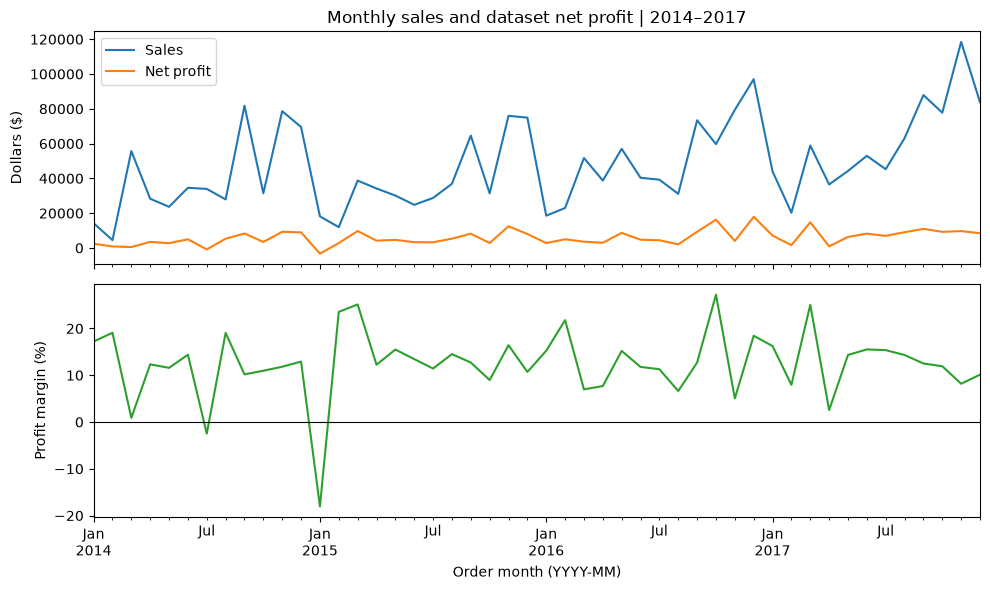

In [25]:
monthly_performance = df.groupby(df['Order Date'].dt.to_period('M')).agg(
    Total_Sales=('Sales', 'sum'), Net_Profit=('Profit', 'sum'))
monthly_performance['Profit_Margin'] = monthly_performance['Net_Profit'] / monthly_performance['Total_Sales'] * 100
monthly_performance.index.name = 'Order month (YYYY-MM)'
assert len(monthly_performance) == 48, 'Expected complete four-year monthly coverage.'

# Show only months needed to support the findings; keep all 48 months in the table above.
highlight_months = monthly_performance.loc[
    monthly_performance['Net_Profit'].lt(0)
    | (monthly_performance.index == monthly_performance['Total_Sales'].idxmax())
    | (monthly_performance.index == monthly_performance['Net_Profit'].idxmax())
    | (monthly_performance.index == monthly_performance['Profit_Margin'].idxmax())
]
show_table(highlight_months, 'Selected year-months | all net-loss months plus sales, profit, and margin maxima; 48 months analyzed')

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
monthly_performance[['Total_Sales', 'Net_Profit']].rename(columns={'Total_Sales': 'Sales', 'Net_Profit': 'Net profit'}).plot(ax=axes[0])
axes[0].set(title='Monthly sales and dataset net profit | 2014–2017', ylabel='Dollars ($)')
monthly_performance['Profit_Margin'].plot(ax=axes[1], color='tab:green')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(ylabel='Profit margin (%)', xlabel='Order month (YYYY-MM)')
fig.tight_layout()
plt.show()

#### Key Findings — Monthly Sales and Profit Analysis

- November 2017 recorded the highest monthly sales (`$118,447.82`), but its profit margin was only 8.18%.
- December 2016 generated the highest monthly net profit (`$17,885.31`), with a profit margin of 18.44%.
- Monthly net losses occurred in July 2014 (`$841.48`) and January 2015 (`$3,281.01`).
- Monthly profit margins varied considerably, ranging from -18.05% in January 2015 to 27.21% in October 2016.
- These results indicate that higher monthly sales do not necessarily correspond to higher profitability.

#### Calendar-Month Sales Across Years

For each named month, average its four year-specific monthly sales totals. Include the observation count and range to show variation; these are not average order values or sums across four years.

In [26]:
calendar_month_summary = monthly_performance.assign(
    Month_Number=monthly_performance.index.month
).groupby('Month_Number').agg(
    Years_Observed=('Total_Sales', 'size'),
    Mean_Monthly_Sales=('Total_Sales', 'mean'),
    Min_Monthly_Sales=('Total_Sales', 'min'),
    Max_Monthly_Sales=('Total_Sales', 'max'),
)
assert calendar_month_summary['Years_Observed'].eq(4).all()
calendar_month_summary.index = calendar_month_summary.index.map(lambda month: calendar.month_name[month])
calendar_month_summary.index.name = 'Calendar month'
show_table(calendar_month_summary.rename(columns={
    'Mean_Monthly_Sales': 'Mean monthly sales ($)',
    'Min_Monthly_Sales': 'Minimum monthly sales ($)',
    'Max_Monthly_Sales': 'Maximum monthly sales ($)',
}), 'Calendar-month sales | arithmetic mean and range of four yearly monthly totals, 2014–2017')

,Years Observed,Mean monthly sales ($),Minimum monthly sales ($),Maximum monthly sales ($)
Calendar month,,,,
January,4,"$23,731.21","$14,236.90","$43,971.37"
February,4,"$14,937.81","$4,519.89","$22,978.81"
March,4,"$51,251.37","$38,726.25","$58,872.35"
April,4,"$34,440.53","$28,295.35","$38,750.04"
May,4,"$38,757.20","$23,648.29","$56,987.73"
June,4,"$38,179.67","$24,797.29","$52,981.73"
July,4,"$36,809.52","$28,765.33","$45,264.42"
August,4,"$39,761.02","$27,909.47","$63,120.89"
September,4,"$76,912.49","$64,595.92","$87,866.65"


**Key findings - calendar-month patterns**

- November has the highest mean monthly sales (`$88,115.27`), followed by December (`$81,323.38`) and September (`$76,912.49`). February has the lowest mean (`$14,937.81`).
- The range columns show that these means conceal differences between years. Only four annual observations support each month; treat this as a planning hypothesis, not a validated seasonal forecast.

<a id="business-insights"></a>

### 5.8 EDA Summary and Business Insights

Translate the preceding evidence into an ordered investigation queue. Priorities reflect observed loss exposure and diagnostic specificity, not a prediction of recoverable profit.

| Priority | Evidence | Concrete next action and decision check |
|---|---|---|
| 1. Review the largest loss pools | Central Office Supplies contributes `$33,484.17` (21.45%) of gross loss; East Technology contributes `$20,997.63` (13.45%). Both remain net profitable. | Ask the category and regional owners to audit negative-profit lines in these two segments by SKU, state, discount, and quantity. Reconcile product costs and pricing exceptions before proposing changes; track both gross loss dollars and net margin so profitable volume is considered. |
| 2. Audit product and discount exceptions | The top 50 composite product groups account for `$89,200.02` of the `$156,131.29` total gross loss (57.13%). Central Furnishings has a net loss of `$3,906.22`; 138 of 205 lines lose money, with mean discounts of 60% on loss lines versus 0% on the 67 positive lines. | Build a review queue from the top-50 groups and the Central Furnishings lines, checking overlap before combining totals. Validate cost inputs, discount approvals, and product-name/ID mappings. Pilot any revised approval rule on comparable products and monitor sales, net margin, and gross loss; the observed discount gap does not justify a blanket discount cut or product removal. |
| 3. Review growth quality before expanding promotions | Sales rose from `$609,205.60` in 2016 to `$733,215.26` in 2017, while margin fell from 13.43% to 12.74%; net profit still rose to `$93,439.27`. Tables has a -8.56% net margin and Machines only 1.79%. | Before repeating 2017 promotions, compare category, region, product mix, and discounts with 2016. Ask commercial owners to explain the margin change and evaluate promotion proposals using expected contribution and volume together. No driver has yet been isolated. |
| 4. Plan peak-month capacity with a profit check | November averages `$88,115.27` in monthly sales across four years, but November 2017 combines record monthly sales of `$118,447.82` with an 8.18% margin. | Use the calendar-month ranges as an initial stock and staffing scenario, then confirm against current demand, lead times, and inventory. Review margin and gross loss alongside sales during peak promotions. Validate forecasting assumptions on later data before setting a seasonal uplift. |

#### Limitations and Interpretation

- This is a historical 2014–2017 extract, not evidence of present-day performance. Four years and four observations per calendar month cannot establish a stable seasonal pattern; no forecast or out-of-sample validation was performed.
- `Profit` is a supplied row-level field. Its cost coverage is not independently verified; summing it is dataset net profit, not proof of company-wide accounting net income. Gross loss is not guaranteed avoidable loss or a savings estimate.
- Discount comparisons are observational, unweighted order-line averages. Product, region, state, quantity, customer, and time mix can confound the relationship. No causal effect or demand response to price changes was estimated.
- Product rankings retain the composite key used above. Thirty-two Product IDs have multiple names; reconcile the product master before treating these groups as unique SKUs. Category-region and product loss pools overlap and must not be added together.
- The 5% margin screen is exploratory. Missing-value, duplicate, date, and numeric checks do not prove source completeness or correct cost allocation. Operational recommendations require current cost, inventory, promotion, and demand information not analyzed here.